In [1]:
import matplotlib
import matplotlib.pylab as pylab
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import scipy.stats as stats
import os

# Exploratory Data Analysis

# 1.1 Basic Description of the Data and Its Characteristics (Valeriia Petrishka)

In [2]:
from pathlib import Path

# CSV files are in ../dataset relative to the src folder
src_dir = Path.cwd() if Path.cwd().name == "src" else Path.cwd() / "src"
dataset_dir = src_dir.parent / "dataset"
gateways_df = pd.read_csv(dataset_dir / "gateways.csv", sep=";")
readings_df = pd.read_csv(dataset_dir / "readings.csv", sep="\t")
units_df = pd.read_csv(dataset_dir / "units.csv")
for name, frame in {"gateways": gateways_df, "readings": readings_df, "units": units_df}.items():
    print(name, frame.shape)
    display(frame.head())

gateways (16000, 10)


,firmware_version,idDepot,gatewayId,date_install,vendor,Ipv4,dbmSignal,lon,idUnit,Technician
0,v2.7.0,46,GW-00000,2023/02/11,Miller-Parker,15.167.175.137,-72.4,-7.17795,1470.0,Fábio Pinto
1,v2.7.0,94,GW-00001,24 Nov 2018,Kent-Webb,60.190.76.185,-59.3,-6.72380,1406.0,Rodrigo Pacheco
2,v2.7.0,61,GW-00002,2018/08/20,Schleich,23.152.231.98,-68.7,-9.23071,1022.0,Camila Coelho
3,v3.4.1,27,GW-00003,2022-08-01,Faria,188.19.209.173,-79.9,-7.92698,178.0,Carina Hering
4,v2.7.0,54,GW-00004,21 Sep 2016,Seifert Seifert GbR,119.17.6.184,-72.1,-7.84725,1062.0,Chad Salazar


readings (15810, 12)


,idUnit,ts_cycle,motorCurrent,dpFilter,oilTemperature,pressureReservoir,pressureOil,rms_vibration,flowmeter,humidityIntake,current_aux,failure
0,U01837,07 Jan 2023,6.52327,16.51122,36.82184,8.76768,3.84876,5.82861,23.79687,41.18050,3.14415,0
1,U01444,2023/10/21,3.35043,31.18794,57.39092,9.41911,4.88801,6.68213,29.59370,11.72450,3.00981,0
2,U01073,"07/17/2023, 05:03:00",3.86973,26.14267,61.13997,7.82343,3.06123,2.90913,24.92436,62.33287,0.84162,0
3,U01469,2023-09-02,3.64275,22.77432,61.45080,8.66640,3.97944,3.14111,29.75494,22.25817,4.11380,0
4,U00271,2023/07/11,5.77419,31.62403,46.30993,9.42113,4.18919,NaN,30.53777,86.07477,3.03859,1


units (2000, 7)


,idDepot,last_overhaul,classDuty,serial_number,Manufacturer,hoursService,idUnit
0,69,2016/04/20,H,FN-1865-92664,Correia,19153.0,1
1,85,2022/09/30,H,VE-5385-79331,Murray PLC,14182.1,2
2,56,2023-08-07,N,RK-8589-24716,Pacheco,10193.1,3
3,93,2020-06-20,heavy,SK-1876-42353,Nascimento,12223.0,4
4,76,"12/15/2023, 00:00:00",N,NK-8717-68406,"Camacho, Lowe and Robinson",3974.3,5


# Gateways

In [3]:
print("Shape:", gateways_df.shape)
print("Dup rows:", gateways_df.duplicated().sum())

Shape: (16000, 10)
Dup rows: 0


In [4]:
overview = pd.DataFrame({
    "dtype":gateways_df.dtypes,
    "non_null":gateways_df.notna().sum(),
    "missing":gateways_df.isna().sum(),
    "unique":gateways_df.nunique(),
})
print(overview)

                    dtype  non_null  missing  unique
firmware_version      str     16000        0       3
idDepot             int64     16000        0     120
gatewayId             str     16000        0   16000
date_install          str     16000        0    9721
vendor                str     16000        0      39
Ipv4                  str     16000        0   16000
dbmSignal         float64     16000        0     589
lon               float64     16000        0   15594
idUnit            float64      2000    14000    2000
Technician            str     16000        0     120


In [5]:
gateways_df.head(10)

,firmware_version,idDepot,gatewayId,date_install,vendor,Ipv4,dbmSignal,lon,idUnit,Technician
0,v2.7.0,46,GW-00000,2023/02/11,Miller-Parker,15.167.175.137,-72.4,-7.17795,1470.0,Fábio Pinto
1,v2.7.0,94,GW-00001,24 Nov 2018,Kent-Webb,60.190.76.185,-59.3,-6.72380,1406.0,Rodrigo Pacheco
2,v2.7.0,61,GW-00002,2018/08/20,Schleich,23.152.231.98,-68.7,-9.23071,1022.0,Camila Coelho
3,v3.4.1,27,GW-00003,2022-08-01,Faria,188.19.209.173,-79.9,-7.92698,178.0,Carina Hering
4,v2.7.0,54,GW-00004,21 Sep 2016,Seifert Seifert GbR,119.17.6.184,-72.1,-7.84725,1062.0,Chad Salazar
5,v1.2.5,17,GW-00005,2024-05-30,Neto S.A.,156.29.124.10,-73.1,-8.95919,1939.0,Herr Dittmar Römer
6,v1.2.5,114,GW-00006,2024/01/24,Marques,54.241.128.51,-63.6,-8.34572,577.0,Joana Henriques-Figueiredo
7,v1.2.5,67,GW-00007,2015/05/01,Gunpf,164.115.43.0,-67.0,-7.43576,1123.0,Angela Watson
8,v3.4.1,15,GW-00008,13 Dec 2021,Kent-Webb,135.214.121.92,-83.4,-8.20020,1727.0,Christopher Mayer
9,v3.4.1,103,GW-00009,2022-02-25,Flowers LLC,132.23.24.31,-88.6,-8.94936,73.0,Rita Harloff


In [6]:
# convert unit ID to nullable integers, preserving missing values
gateways_df["idUnit"] = gateways_df["idUnit"].astype("Int64")
gateways_df = gateways_df.drop(columns=["Ipv4"], errors="ignore")
gateways_df.head(10)

,firmware_version,idDepot,gatewayId,date_install,vendor,dbmSignal,lon,idUnit,Technician
0,v2.7.0,46,GW-00000,2023/02/11,Miller-Parker,-72.4,-7.17795,1470,Fábio Pinto
1,v2.7.0,94,GW-00001,24 Nov 2018,Kent-Webb,-59.3,-6.72380,1406,Rodrigo Pacheco
2,v2.7.0,61,GW-00002,2018/08/20,Schleich,-68.7,-9.23071,1022,Camila Coelho
3,v3.4.1,27,GW-00003,2022-08-01,Faria,-79.9,-7.92698,178,Carina Hering
4,v2.7.0,54,GW-00004,21 Sep 2016,Seifert Seifert GbR,-72.1,-7.84725,1062,Chad Salazar
5,v1.2.5,17,GW-00005,2024-05-30,Neto S.A.,-73.1,-8.95919,1939,Herr Dittmar Römer
6,v1.2.5,114,GW-00006,2024/01/24,Marques,-63.6,-8.34572,577,Joana Henriques-Figueiredo
7,v1.2.5,67,GW-00007,2015/05/01,Gunpf,-67.0,-7.43576,1123,Angela Watson
8,v3.4.1,15,GW-00008,13 Dec 2021,Kent-Webb,-83.4,-8.20020,1727,Christopher Mayer
9,v3.4.1,103,GW-00009,2022-02-25,Flowers LLC,-88.6,-8.94936,73,Rita Harloff


# Univariate analysis

## Continuous attributes

In [7]:
gateways_df.describe()

,idDepot,dbmSignal,lon,idUnit
count,16000.000000,16000.000000,16000.000000,2000.0
mean,59.320062,-69.845756,-7.749522,1000.5
std,34.328884,9.979199,0.890287,577.494589
min,0.000000,-110.000000,-9.299800,1.0
25%,30.000000,-76.600000,-8.515750,500.75
50%,59.000000,-69.900000,-7.754480,1000.5
75%,89.000000,-63.000000,-6.976895,1500.25
max,119.000000,-40.000000,-6.200200,2000.0


array([[<Axes: title={'center': 'idDepot'}>,
        <Axes: title={'center': 'dbmSignal'}>],
       [<Axes: title={'center': 'lon'}>,
        <Axes: title={'center': 'idUnit'}>]], dtype=object)

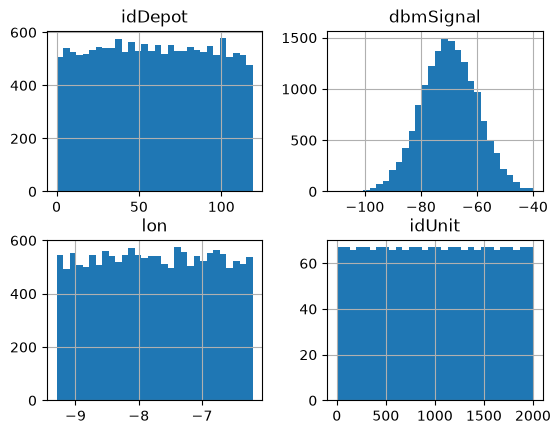

In [8]:
gateways_df.hist(bins=30)

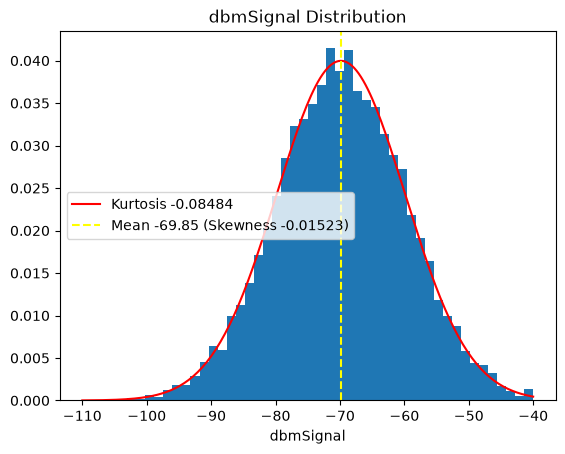

In [9]:
s=gateways_df["dbmSignal"]

mu,sigma=stats.norm.fit(s)
norm=stats.norm(mu,sigma)
x=np.linspace(s.min(),s.max(),200)

plt.hist(s,bins=50,density=True)
plt.plot(x,norm.pdf(x),"r",label="Kurtosis %.5f" % stats.kurtosis(s))
plt.axvline(s.mean(),color="yellow",ls="--",label="Mean %.2f (Skewness %.5f)" % (s.mean(),stats.skew(s)))
plt.xlabel("dbmSignal")
plt.title("dbmSignal Distribution")
plt.legend()
plt.show()

## Categorical attributes

<Axes: xlabel='firmware_version'>

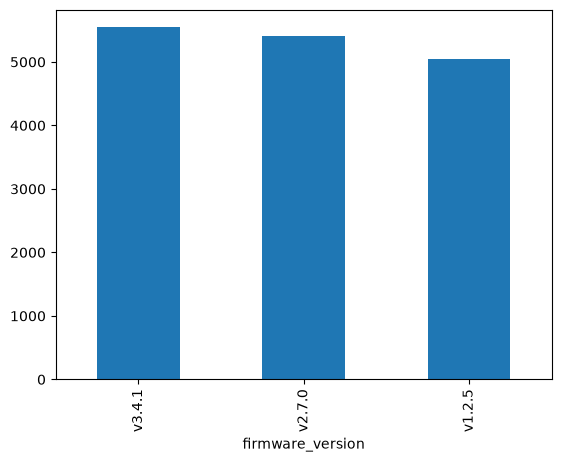

In [10]:
gateways_df.firmware_version.value_counts().plot(kind='bar')

# Bivariate analysis

## Continuous - continuous

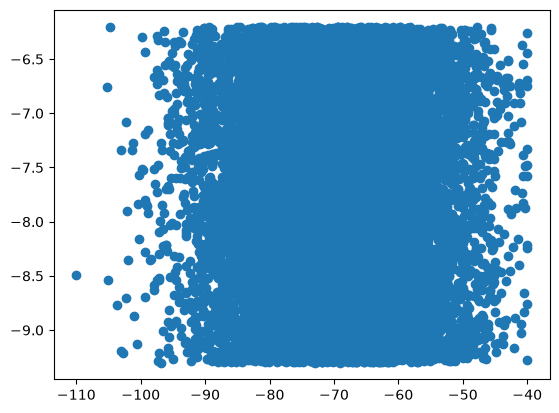

In [11]:
plt.scatter(gateways_df.dbmSignal, gateways_df.lon)

<Axes: >

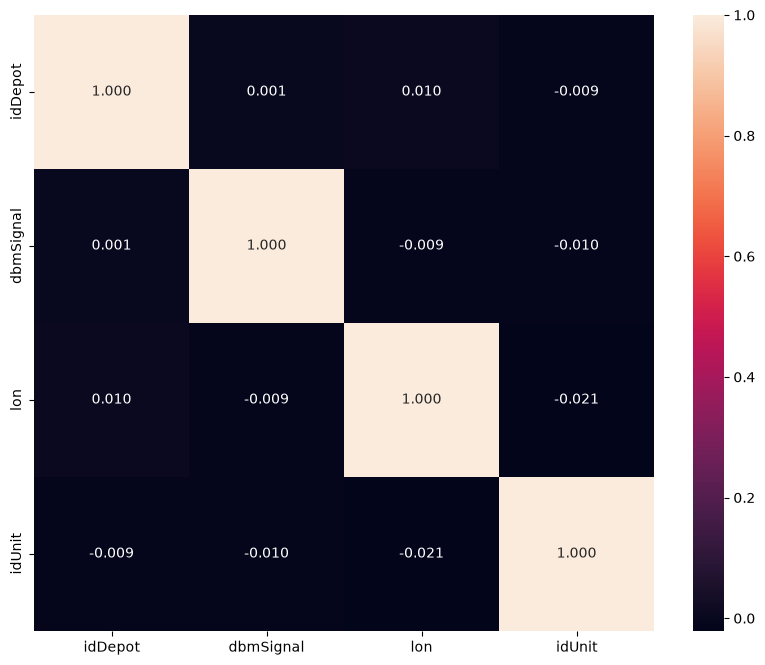

In [12]:
fig, ax = plt.subplots(figsize=(10,8))
sns.heatmap(gateways_df.corr(numeric_only=True), ax=ax, annot=True, fmt=".3f")

## Continuous - categorical

<Axes: xlabel='dbmSignal', ylabel='firmware_version'>

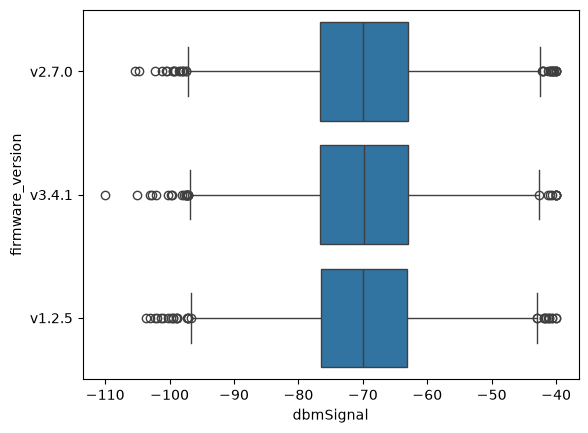

In [13]:
sns.boxplot(x="dbmSignal", y="firmware_version", data=gateways_df)

## Categorical - categorical

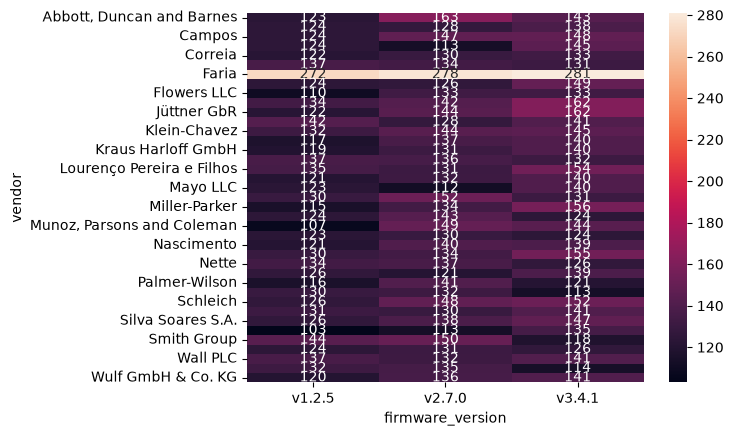

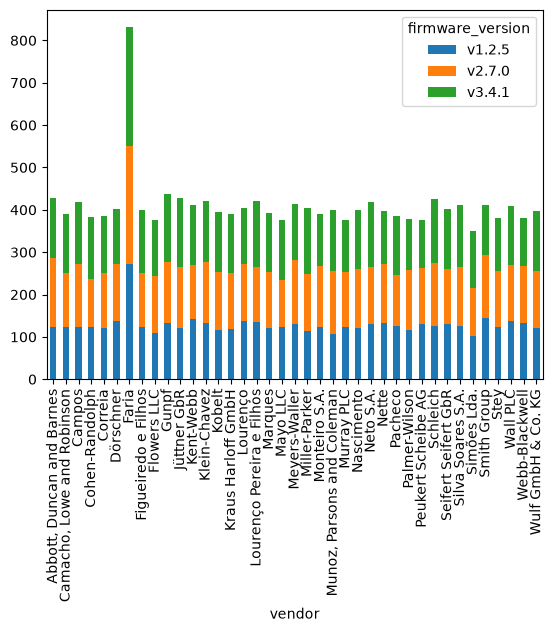

In [14]:
pair=pd.crosstab(index=gateways_df["vendor"],columns=gateways_df["firmware_version"])
sns.heatmap(pair, annot=True, fmt="d")

pair=pd.crosstab(index=gateways_df["vendor"],columns=gateways_df["firmware_version"]).plot.bar(stacked=True)

## Readings

In [15]:
display(readings_df.head())

,idUnit,ts_cycle,motorCurrent,dpFilter,oilTemperature,pressureReservoir,pressureOil,rms_vibration,flowmeter,humidityIntake,current_aux,failure
0,U01837,07 Jan 2023,6.52327,16.51122,36.82184,8.76768,3.84876,5.82861,23.79687,41.18050,3.14415,0
1,U01444,2023/10/21,3.35043,31.18794,57.39092,9.41911,4.88801,6.68213,29.59370,11.72450,3.00981,0
2,U01073,"07/17/2023, 05:03:00",3.86973,26.14267,61.13997,7.82343,3.06123,2.90913,24.92436,62.33287,0.84162,0
3,U01469,2023-09-02,3.64275,22.77432,61.45080,8.66640,3.97944,3.14111,29.75494,22.25817,4.11380,0
4,U00271,2023/07/11,5.77419,31.62403,46.30993,9.42113,4.18919,NaN,30.53777,86.07477,3.03859,1


In [16]:
readings_df.shape

(15810, 12)

## Units

In [17]:
display(units_df.head())

,idDepot,last_overhaul,classDuty,serial_number,Manufacturer,hoursService,idUnit
0,69,2016/04/20,H,FN-1865-92664,Correia,19153.0,1
1,85,2022/09/30,H,VE-5385-79331,Murray PLC,14182.1,2
2,56,2023-08-07,N,RK-8589-24716,Pacheco,10193.1,3
3,93,2020-06-20,heavy,SK-1876-42353,Nascimento,12223.0,4
4,76,"12/15/2023, 00:00:00",N,NK-8717-68406,"Camacho, Lowe and Robinson",3974.3,5


## 1.2 Problems, data integration, and data cleaning (Oleh Kysil)

The prediction target is `failure`, recorded for each measurement cycle. Keep one row per reading and attach unit and gateway metadata through `idUnit`.

### Normalize formats and remove redundant records

Reading IDs such as `U01837` and unit ID `1837` represent the same unit. Parse mixed dates into datetime values, date-only values have no known time and are represented at midnight. Unify the clear letter/word duty variants, leaving `med` and undocumented numeric codes separate

In [18]:
tables = {"gateways": gateways_df, "readings": readings_df, "units": units_df}
date_columns = {"gateways": "date_install", "readings": "ts_cycle", "units": "last_overhaul"}
normalized = {}

for name, table in tables.items():
    # remove exact duplicate rows so repeated copies do not bias the analysis.
    frame = table.drop_duplicates().copy()
    for column in frame.select_dtypes(include=["object", "string"]).columns:
        frame[column] = frame[column].astype("string").str.strip().replace("", pd.NA)
    for column in [c for c in ["idUnit", "idDepot"] if c in frame]:
        key_text = frame[column].astype("string")
        if name == "readings" and column == "idUnit":
            # remove the U prefix to match the integer IDs in the metadata tables
            key_text = key_text.str.replace(r"^U", "", regex=True)
        numeric = pd.to_numeric(key_text, errors="coerce")
        valid = numeric.notna() & np.isfinite(numeric) & numeric.ge(0) & numeric.mod(1).eq(0)
        # replace invalid IDs with missing value, zero is a valid depot ID
        frame[column] = numeric.where(valid).astype("Int64")
    frame[date_columns[name]] = pd.to_datetime(frame[date_columns[name]], format="mixed", errors="coerce")
    if name == "units":
        frame["classDuty"] = frame["classDuty"].str.lower().replace(
            {"h": "heavy", "l": "light", "n": "normal"})
    # remove full-row duplicates that become identical after format normalization.
    normalized[name] = frame.drop_duplicates().copy()

gateways_clean = normalized["gateways"]
readings_clean = normalized["readings"]
units_clean = normalized["units"]
display(gateways_clean)
display(readings_clean)
display(units_clean)

,firmware_version,idDepot,gatewayId,date_install,vendor,dbmSignal,lon,idUnit,Technician
0,v2.7.0,46,GW-00000,2023-02-11,Miller-Parker,-72.4,-7.17795,1470,Fábio Pinto
1,v2.7.0,94,GW-00001,2018-11-24,Kent-Webb,-59.3,-6.72380,1406,Rodrigo Pacheco
2,v2.7.0,61,GW-00002,2018-08-20,Schleich,-68.7,-9.23071,1022,Camila Coelho
3,v3.4.1,27,GW-00003,2022-08-01,Faria,-79.9,-7.92698,178,Carina Hering
4,v2.7.0,54,GW-00004,2016-09-21,Seifert Seifert GbR,-72.1,-7.84725,1062,Chad Salazar
...,...,...,...,...,...,...,...,...,...
15995,v3.4.1,99,GW-15995,2024-06-11,Simões Lda.,-71.4,-6.50930,<NA>,Meghan Patel
15996,v2.7.0,4,GW-15996,2022-07-16,Webb-Blackwell,-61.9,-7.13180,<NA>,Brian Coelho
15997,v2.7.0,30,GW-15997,2024-05-06,Palmer-Wilson,-68.6,-7.38450,<NA>,André da Almeida
15998,v3.4.1,68,GW-15998,2020-07-26,Kraus Harloff GmbH,-68.8,-7.79738,<NA>,Dr. Adriana Cichorius B.Eng.


,idUnit,ts_cycle,motorCurrent,dpFilter,oilTemperature,pressureReservoir,pressureOil,rms_vibration,flowmeter,humidityIntake,current_aux,failure
0,1837,2023-01-07 00:00:00,6.52327,16.51122,36.82184,8.76768,3.84876,5.82861,23.79687,41.18050,3.14415,0
1,1444,2023-10-21 00:00:00,3.35043,31.18794,57.39092,9.41911,4.88801,6.68213,29.59370,11.72450,3.00981,0
2,1073,2023-07-17 05:03:00,3.86973,26.14267,61.13997,7.82343,3.06123,2.90913,24.92436,62.33287,0.84162,0
3,1469,2023-09-02 00:00:00,3.64275,22.77432,61.45080,8.66640,3.97944,3.14111,29.75494,22.25817,4.11380,0
4,271,2023-07-11 00:00:00,5.77419,31.62403,46.30993,9.42113,4.18919,NaN,30.53777,86.07477,3.03859,1
...,...,...,...,...,...,...,...,...,...,...,...,...
15571,1715,2023-10-03 00:00:00,8.10634,23.75623,38.55659,8.46866,4.01351,NaN,20.45578,81.22487,3.44488,0
15572,1355,2023-07-19 06:48:00,6.25650,22.18533,43.43464,8.57624,3.80081,2.38926,32.42021,21.72667,2.03999,0
15573,971,2023-11-12 14:06:00,7.93083,28.02206,65.17459,9.23116,3.58476,4.64216,30.77456,55.17802,1.72297,0
15574,159,2023-11-29 00:00:00,5.95949,39.84336,65.75819,8.57829,3.73022,2.46270,27.35111,58.52541,2.79068,0


,idDepot,last_overhaul,classDuty,serial_number,Manufacturer,hoursService,idUnit
0,69,2016-04-20,heavy,FN-1865-92664,Correia,19153.0,1
1,85,2022-09-30,heavy,VE-5385-79331,Murray PLC,14182.1,2
2,56,2023-08-07,normal,RK-8589-24716,Pacheco,10193.1,3
3,93,2020-06-20,heavy,SK-1876-42353,Nascimento,12223.0,4
4,76,2023-12-15,normal,NK-8717-68406,"Camacho, Lowe and Robinson",3974.3,5
...,...,...,...,...,...,...,...
1995,73,2024-07-28,light,GI-2985-30885,Klein-Chavez,3345.0,1996
1996,76,2023-07-01,light,OG-0205-65156,Mayo LLC,5703.6,1997
1997,58,2021-03-21,normal,FA-1584-67680,Webb-Blackwell,11374.7,1998
1998,105,2021-09-15,1,JS-9450-43578,Pacheco,7251.0,1999


### Abnormal measurements

Replace invalid measurements with missing values. Current values of `99` are suspicious but are not confirmed errors

In [19]:
sensor_columns = ["motorCurrent", "dpFilter", "oilTemperature", "pressureReservoir",
                  "pressureOil", "rms_vibration", "flowmeter", "humidityIntake", "current_aux"]
for column in sensor_columns:
    values = readings_clean[column]
    invalid = values.notna() & ~np.isfinite(values)
    if column == "oilTemperature":
        invalid |= values.eq(-999)
    if column == "humidityIntake":
        invalid |= values.notna() & ~values.between(0, 100)
    # remove non-finite values, the -999 temperature sentinel, and impossible humidity values
    readings_clean.loc[invalid, column] = np.nan

invalid_hours = units_clean["hoursService"].lt(0) | (
    units_clean["hoursService"].notna() & ~np.isfinite(units_clean["hoursService"]))
# remove negative or infinite service hours by replacing them with missing values
units_clean.loc[invalid_hours, "hoursService"] = np.nan
invalid_longitude = gateways_clean["lon"].notna() & ~gateways_clean["lon"].between(-180, 180)
# remove coordinates outside the valid longitude range.
gateways_clean.loc[invalid_longitude, "lon"] = np.nan
display(gateways_clean)

,firmware_version,idDepot,gatewayId,date_install,vendor,dbmSignal,lon,idUnit,Technician
0,v2.7.0,46,GW-00000,2023-02-11,Miller-Parker,-72.4,-7.17795,1470,Fábio Pinto
1,v2.7.0,94,GW-00001,2018-11-24,Kent-Webb,-59.3,-6.72380,1406,Rodrigo Pacheco
2,v2.7.0,61,GW-00002,2018-08-20,Schleich,-68.7,-9.23071,1022,Camila Coelho
3,v3.4.1,27,GW-00003,2022-08-01,Faria,-79.9,-7.92698,178,Carina Hering
4,v2.7.0,54,GW-00004,2016-09-21,Seifert Seifert GbR,-72.1,-7.84725,1062,Chad Salazar
...,...,...,...,...,...,...,...,...,...
15995,v3.4.1,99,GW-15995,2024-06-11,Simões Lda.,-71.4,-6.50930,<NA>,Meghan Patel
15996,v2.7.0,4,GW-15996,2022-07-16,Webb-Blackwell,-61.9,-7.13180,<NA>,Brian Coelho
15997,v2.7.0,30,GW-15997,2024-05-06,Palmer-Wilson,-68.6,-7.38450,<NA>,André da Almeida
15998,v3.4.1,68,GW-15998,2020-07-26,Kraus Harloff GmbH,-68.8,-7.79738,<NA>,Dr. Adriana Cichorius B.Eng.


### Integrate the tables

Use many-to-one joins to prevent row multiplication. Exclude unresolved reading IDs, invalid labels, and conflicting labels for the same unit/date. 

In [20]:
cycle_keys = ["idUnit", "ts_cycle"]
conflicting_labels = readings_clean.groupby(cycle_keys, dropna=False)["failure"].transform("nunique").gt(1)
valid_readings = readings_clean["idUnit"].notna() & readings_clean["ts_cycle"].notna()
valid_readings &= readings_clean["failure"].isin([0, 1]) & ~conflicting_labels
# remove readings with invalid IDs/dates/labels or unresolved contradictory cycle labels
readings_for_merge = readings_clean.loc[valid_readings].copy()

# exclude unassigned gateways from the unit join; a depot does not identify a unique unit
linked_gateways = gateways_clean.loc[gateways_clean["idUnit"].notna()].copy()
gateway_metadata = linked_gateways.rename(columns={c: f"gateway_{c}" for c in linked_gateways if c != "idUnit"})
integrated_df = readings_for_merge.merge(units_clean, on="idUnit", how="left",
                                         validate="many_to_one", indicator="unit_match")
# remove readings whose IDs have no matching unit metadata
cleaned_df = integrated_df.loc[integrated_df["unit_match"].eq("both")].copy()
# remove the temporary merge indicator once unmatched readings have been excluded
cleaned_df = cleaned_df.drop(columns="unit_match")
cleaned_df = cleaned_df.merge(gateway_metadata, on="idUnit", how="left", validate="many_to_one")
display(cleaned_df)

,idUnit,ts_cycle,motorCurrent,dpFilter,oilTemperature,pressureReservoir,pressureOil,rms_vibration,flowmeter,humidityIntake,...,Manufacturer,hoursService,gateway_firmware_version,gateway_idDepot,gateway_gatewayId,gateway_date_install,gateway_vendor,gateway_dbmSignal,gateway_lon,gateway_Technician
0,1837,2023-01-07 00:00:00,6.52327,16.51122,36.82184,8.76768,3.84876,5.82861,23.79687,41.18050,...,Meyers-Waller,15380.2,v2.7.0,48,GW-01390,2020-03-02,Figueiredo e Filhos,-76.8,-8.39000,Ahmed Bachmann
1,1444,2023-10-21 00:00:00,3.35043,31.18794,57.39092,9.41911,4.88801,6.68213,29.59370,11.72450,...,Nascimento,17358.0,v3.4.1,89,GW-00829,2020-04-23,Murray PLC,-80.2,-8.31471,Gustavo Andrade
2,1073,2023-07-17 05:03:00,3.86973,26.14267,61.13997,7.82343,3.06123,2.90913,24.92436,62.33287,...,Meyers-Waller,19389.9,v2.7.0,26,GW-01692,2018-01-14,Miller-Parker,-55.7,-8.43676,Henry Salinas
3,1469,2023-09-02 00:00:00,3.64275,22.77432,61.45080,8.66640,3.97944,3.14111,29.75494,22.25817,...,Campos,3564.2,v3.4.1,39,GW-01796,2019-01-01,"Camacho, Lowe and Robinson",-56.5,-7.76988,Inês Matos
4,271,2023-07-11 00:00:00,5.77419,31.62403,46.30993,9.42113,4.18919,NaN,30.53777,86.07477,...,Smith Group,45000.0,v2.7.0,19,GW-01375,2017-12-06,Marques,-75.7,-6.85225,Ricardo Carvalho
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15392,1715,2023-10-03 00:00:00,8.10634,23.75623,38.55659,8.46866,4.01351,NaN,20.45578,81.22487,...,Faria,23388.9,v2.7.0,109,GW-01956,2017-02-18,Faria,-68.9,-8.73926,Sofia Neves
15393,1355,2023-07-19 06:48:00,6.25650,22.18533,43.43464,8.57624,3.80081,2.38926,32.42021,21.72667,...,Wulf GmbH & Co. KG,10316.3,v3.4.1,103,GW-01605,2019-12-21,Seifert Seifert GbR,-86.8,-8.20242,Destiny Wilson
15394,971,2023-11-12 14:06:00,7.93083,28.02206,65.17459,9.23116,3.58476,4.64216,30.77456,55.17802,...,Pacheco,8590.6,v1.2.5,91,GW-00660,2022-09-26,Nette,-69.0,-8.88391,Andrea Willis
15395,159,2023-11-29 00:00:00,5.95949,39.84336,65.75819,8.57829,3.73022,2.46270,27.35111,58.52541,...,Mayo LLC,10430.7,v2.7.0,40,GW-01689,2015-04-29,Wulf GmbH & Co. KG,-82.8,-7.41809,Mr. Jeremy Davis


### Compare two outlier treatments

Apply IQR removal and 5th/95th percentile clipping. Missing values alone are not outliers. Keep plausible extremes in `cleaned_df`, since they may carry a failure signal

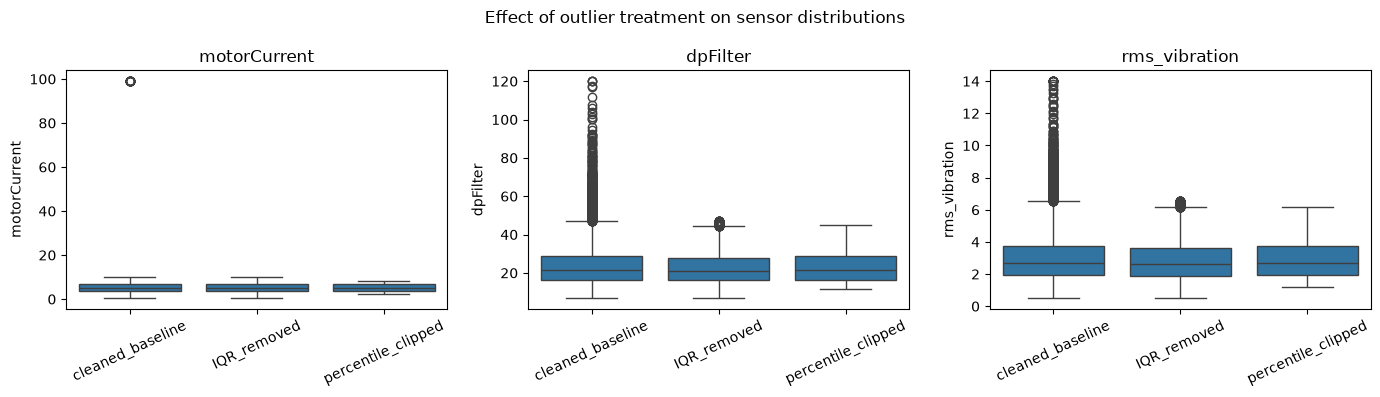

In [21]:
sensor_values = cleaned_df[sensor_columns]
q1, q3 = sensor_values.quantile(0.25), sensor_values.quantile(0.75)
iqr = q3 - q1
iqr_lower, iqr_upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
iqr_flags = sensor_values.lt(iqr_lower, axis="columns") | sensor_values.gt(iqr_upper, axis="columns")
# remove a reading from this alternative if any observed sensor exceeds its IQR fences
iqr_removed_df = cleaned_df.loc[~iqr_flags.any(axis=1)].copy()

p05, p95 = sensor_values.quantile(0.05), sensor_values.quantile(0.95)
clipped_df = cleaned_df.copy()
# replace extreme sensor values with the 5th/95th percentile boundaries; keep rows and missing values
clipped_df[sensor_columns] = sensor_values.clip(lower=p05, upper=p95, axis="columns")

variants = {"cleaned_baseline": cleaned_df, "IQR_removed": iqr_removed_df, "percentile_clipped": clipped_df}
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, column in zip(axes, ["motorCurrent", "dpFilter", "rms_vibration"]):
    plot_data = pd.concat([frame[[column]].assign(treatment=name) for name, frame in variants.items()], ignore_index=True)
    sns.boxplot(data=plot_data, x="treatment", y=column, ax=ax)
    ax.tick_params(axis="x", rotation=25)
    ax.set_xlabel("")
    ax.set_title(column)
fig.suptitle("Effect of outlier treatment on sensor distributions")
plt.tight_layout()
plt.show()

## 1.3 hypothesis testing and statistical power

- **Vibration:** Hypothesis 1: the mean within-unit difference in `rms_vibration` between failure and non-failure states is zero
- Hypothesis 2: it differs from zero
- **Oil pressure:** the same H1/H2 for `pressureOil`

average observed readings within each unit/state, then apply two-sided paired t-tests to units observed in both states, giving each unit equal weight and avoiding treating its cycles as independent samples

use `cleaned_df` without outliers removed. tests assume independent units and approximately normal sampling distributions of mean differences, supported by the large number of pairs. Missing values may bias results, particularly for vibration

apply Bonferroni correction for two tests at overall alpha = 0.05 and report matching 97.5% confidence intervals

check power against a specified paired effect d = 0.2, measured in standard deviations of within-unit differences, with an 80% target. this is an example sensitivity threshold

methods: [paired t-test](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_rel.html), [paired-test power](https://www.statsmodels.org/stable/generated/statsmodels.stats.power.TTestPower.html)

In [22]:
from statsmodels.stats.power import TTestPower

alpha = 0.05
test_alpha = alpha / 2
target_d = 0.2
power_model = TTestPower()
results = []

for sensor in ["rms_vibration", "pressureOil"]:
    paired = cleaned_df.groupby(["idUnit", "failure"])[sensor].mean().unstack()
    # exclude units without observed measurements in both states for this sensor
    paired = paired.dropna(subset=[0, 1])
    difference = paired[1] - paired[0]
    test = stats.ttest_rel(paired[1], paired[0], alternative="two-sided")
    interval = test.confidence_interval(confidence_level=1 - test_alpha)
    power = power_model.power(effect_size=target_d, nobs=len(paired),
                              alpha=test_alpha, alternative="two-sided")
    results.append({"sensor": sensor, "units": len(paired),
                    "mean_no_failure": paired[0].mean(), "mean_failure": paired[1].mean(),
                    "difference": difference.mean(),
                    "ci_97.5%": f"[{interval.low:.3f}, {interval.high:.3f}]",
                    "paired_d": difference.mean() / difference.std(ddof=1),
                    "p_adjusted": min(1.0, 2 * test.pvalue),
                    "power_d_0.2": power,
                    "effect_d_0.2": target_d * difference.std(ddof=1)})

hypothesis_results = pd.DataFrame(results).set_index("sensor")
display(hypothesis_results.round(4))
for sensor, row in hypothesis_results.iterrows():
    decision = "reject H0" if row["p_adjusted"] < alpha else "do not reject H0"
    direction = "higher" if row["difference"] > 0 else "lower"
    support = "sufficient" if row["power_d_0.2"] >= 0.8 else "insufficient"
    print(f"{sensor}: {decision}; failure mean is {direction} by {abs(row['difference']):.3f}; "
          f"power for d=0.2 is {row['power_d_0.2']:.1%} ({support})")

,units,mean_no_failure,mean_failure,difference,ci_97.5%,paired_d,p_adjusted,power_d_0.2,effect_d_0.2
sensor,,,,,,,,,
rms_vibration,1002,3.0282,3.3227,0.2945,"[0.171, 0.418]",0.1686,0.0,1.0,0.3494
pressureOil,1114,3.7168,3.5875,-0.1293,"[-0.168, -0.090]",-0.2225,0.0,1.0,0.1162


rms_vibration: reject H0; failure mean is higher by 0.295; power for d=0.2 is 100.0% (sufficient)
pressureOil: reject H0; failure mean is lower by 0.129; power for d=0.2 is 100.0% (sufficient)


These associations apply to units with observed measurements in both states. They do not establish causation or future prediction accuracy

Leave both sensors as candidate predictors and evaluate them during model validation. Power describes detection of the specified d = 0.2 under the paired-test assumptions, not every smaller effect